# TOT_Skewness: 電子の飛跡(散乱点・方向・飛程)

ストリップ × クロックのヒットから、反跳電子の 3 次元の飛跡を作り、**散乱点 `Pe`、電子の方向 `Ve`、飛程 `Len`** を求めます。
FADC の電荷は使わないので、`CalcFADC` の結果によらず、ヒットのあるイベントはすべて処理します(ヒットが無ければ `AS_SKIP`)。

| 手順 | 中身 |
|---|---|
| 1. TOT 補正 | ストリップごとに、続いて鳴ったクロックの範囲 [clk_min, clk_max] を 1 つのヒットにまとめ、TOT = clk_max − clk_min から立ち上がりの時刻を補正する。アノード: clk_min + 1.290 + 0.4329 TOT、カソード: clk_min + 0.698 + 0.4179 TOT |
| 2. 3 次元の同時計数 | 同じパネルで、補正した時刻の差が 4 クロック以内のアノードとカソードのヒットの組を、飛跡の点 (a, c, t) にする |
| 3. 座標 | (a, c) をパネルごとの向きで (x, y) [mm]、t を z = `pitch_z` × (t − `clock_offset`) + `z_gem_mm`(10 mm、GEM 面)にする(0_Introduction と同じ座標) |
| 4. 飛程 | 点群の x, y, z の範囲の対角線の長さ `Len` |
| 5. skewness | x と y の分布(ストリップ間隔のビン、`rise` = 点のあるビンの数で割る)の 3 次の歪み。電子は止まる所で多く電離するので、分布は始点の反対側に偏る |
| 6. 散乱点 | 歪みの大きい方の軸で、歪みの符号から始点の側の端の点を `Pe` にする |
| 7. 方向 | `Pe` の周り 10 mm の点で x-z, y-z の傾き(dz/dx, dz/dy)をフィットし、`Ve` = 符号 × (1/傾き_x, 1/傾き_y, 1) にする。単位ベクトルではなく、使う側で `.Unit()` する(SMILE_tool_box、EricaNext_try と同じ) |

| 出力 | 中身 |
|---|---|
| `TOT_Skewness/tot_skewness`(TTree) | `Pe[3]`, `Ve[3]`(方向のベクトル。長さに意味は無い), `Len` [mm], `skewness_x`, `skewness_y`, `can`(点の数), `cloud_x/y/z`(点群、`flag_save_cloud`) |
| `TOT_Skewness/TPC_Map_xz`, `TPC_Map_yz` | 飛跡の両端の x-z, y-z |
| 印 | `TOT_Len_TRA`, `TOT_Skewness`, `TOT_Pe_TRA`, `TOT_Ve_TRA`(`Reconstruct` が使う) |

TOT 補正の係数と skewness のオフセットは、SMILE-2+ の値のままです(コードの中に書いてある)。

In [1]:
import os, sys, json, subprocess
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import ROOT
ROOT.gROOT.SetBatch(True)

# リポジトリの場所、チェーンの実行スクリプト、設定ファイル(config/*.json)の読み込み
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "run_script" / "run_chain.py").exists())
RUN_CHAIN = REPO / "run_script" / "run_chain.py"
sys.path.insert(0, str(REPO / "config"))
import ericanext_config as ec
CACHE = REPO / "tutorials" / "cache"   # チェーンの出力の置き場(チュートリアル間で共有、git には入れない)
CACHE.mkdir(exist_ok=True)

def th2(h):
    """ROOT の TH2 -> (中身 [x のビン, y のビン], x のビンの端, y のビンの端)"""
    nx, ny = h.GetNbinsX(), h.GetNbinsY()
    dt = np.float32 if h.InheritsFrom("TArrayF") else np.float64   # TH2F / TH2D
    a = np.frombuffer(h.GetArray(), dtype=dt, count=(nx + 2) * (ny + 2)).reshape(ny + 2, nx + 2).astype(float)
    ex = np.array([h.GetXaxis().GetBinLowEdge(i) for i in range(1, nx + 2)])
    ey = np.array([h.GetYaxis().GetBinLowEdge(i) for i in range(1, ny + 2)])
    return a[1:-1, 1:-1].T.copy(), ex, ey

def th1(h):
    """ROOT の TH1 -> (中身, ビンの中心)"""
    n = h.GetNbinsX()
    return np.array([h.GetBinContent(i) for i in range(1, n + 1)]), np.array([h.GetBinCenter(i) for i in range(1, n + 1)])

def vec(column):
    """RDataFrame.AsNumpy() の配列型の列 -> numpy の配列のリスト"""
    return [np.asarray(v) for v in column]

def show_params(config, module):
    """設定ファイルの、あるモジュールのパラメータを、説明(_doc)と単位(_units)つきで表示する"""
    p = json.load(open(REPO / "config" / f"{config}.json"))["parameters"][module]
    doc, units = p.get("_doc", {}), p.get("_units", {})
    for k, v in p.items():
        if k.startswith("_"):
            continue
        u = f" [{units[k]}]" if k in units else ""
        print(f"{k} = {json.dumps(v, ensure_ascii=False)}{u}\n    {doc.get(k, '')}")

## 1. データの準備

2026-06-23 の TPC の較正データ **`run_20260623T072649Z`**(TPC_cal、アノード 12 枚・カソード 11 枚、約 4 GB、約 228 秒、約 10 万イベント)を使います。
解析用の計算機ではリポジトリの `test.data/` にあります(git には入れていない)。ほかの場所にあるときは、環境変数 `SMILE3_TPC_DATA` にランのディレクトリを設定してください。
1 つのディレクトリにアノードとカソードの全ボードが入っているので、`ReadData` がそのまま読めます
(FM のランのように 2 つの storage に分かれているときは、シンボリックリンクで 1 つのディレクトリに集める)。

このランは uPIC0〜2 のレートが安定していて、uPIC3 は電荷がほとんど出ていません。最後の約 10 秒は全 uPIC のレートが跳ね上がる(原因は不明。Notion の「TPC 確認図と QL」)ので、
ここでは先頭の 50000 イベント(約 110 秒)を使います。

In [2]:
RUN_DIR = Path(os.environ.get("SMILE3_TPC_DATA", REPO / "test.data" / "run_20260623T072649Z"))
print("OK     " if RUN_DIR.is_dir() else "MISSING", RUN_DIR)
meta = json.load(open(RUN_DIR / "run_meta.json"))
print("mode:", meta["mode"], " boards:", len(meta["active_detectors"]))

OK      /home/onoda/ANLNext/Erica_git_dev/EricaNext/test.data/run_20260623T072649Z
mode: TPC_cal  boards: 23


## 2. チェーンを流す

設定ファイル `smile3_tpc_only`(`ReadData → CalcFADC → TPC_Calibration → TOT_Skewness`)に、図を作るパラメータを足して先頭 50000 イベントを流します(1 分ほど)。
ターミナルでは、リポジトリの `run_script` で次を実行するのと同じです。

```bash
python3 run_chain.py smile3_tpc_only -o tpc_20260623.root -n 50000 --data-dir ../test.data/run_20260623T072649Z \
    --set ReadData.Image_A_C=true \
    --set TPC_Calibration.Image_XY_TH=true --set TPC_Calibration.Spectrum_TH=true
```

生の波形とヒットは、`smile3_raw`(`ReadData → RawTreeWriter_sm3`)で先頭 5000 イベントをツリーに書いたものから読みます。
出力は `tutorials/cache/` に置き、既にあれば流し直しません(TPC のチュートリアルで共有)。

In [3]:
def run_chain(config, out, *args):
    """run_chain.py を実行する(出力が既にあれば何もしない)。ログを返す"""
    cmd = [sys.executable, str(RUN_CHAIN), config, "-o", str(out), "--data-dir", str(RUN_DIR), *args]
    print(" ".join(cmd))
    if out.exists():
        return ""
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode != 0:
        print(r.stdout[-3000:], r.stderr[-3000:])
    r.check_returncode()
    (out.parent / (out.name + ".log")).write_text(r.stdout)
    return r.stdout

OUT = CACHE / "tpc_20260623.root"
run_chain("smile3_tpc_only", OUT, "-n", "50000",
          "--set", "ReadData.Image_A_C=true",
          "--set", "TPC_Calibration.Image_XY_TH=true", "--set", "TPC_Calibration.Spectrum_TH=true")
OUT_RAW = CACHE / "tpc_20260623_raw.root"
run_chain("smile3_raw", OUT_RAW, "-n", "5000")
F = ROOT.TFile(str(OUT))

def evs_table(log_path):
    """チェーンのログから、イベント選択(evs)の数の表を取り出す"""
    lines = open(log_path).read().split("Result of Event Selections")[1].splitlines()
    rows = [l.split() for l in lines if len(l.split()) == 3 and l.split()[1].isdigit()]
    return {r[0]: int(r[1]) for r in rows}

/usr/bin/python3 /home/onoda/ANLNext/Erica_git_dev/EricaNext/run_script/run_chain.py smile3_tpc_only -o /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/tpc_20260623.root --data-dir /home/onoda/ANLNext/Erica_git_dev/EricaNext/test.data/run_20260623T072649Z -n 50000 --set ReadData.Image_A_C=true --set TPC_Calibration.Image_XY_TH=true --set TPC_Calibration.Spectrum_TH=true
/usr/bin/python3 /home/onoda/ANLNext/Erica_git_dev/EricaNext/run_script/run_chain.py smile3_raw -o /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/tpc_20260623_raw.root --data-dir /home/onoda/ANLNext/Erica_git_dev/EricaNext/test.data/run_20260623T072649Z -n 5000


## 3. 1 イベントの点群

`cloud_x/y/z` から、点の多いイベントを 1 つ選んで描きます。赤い点が `Pe`、矢印が `Ve` の向き(正規化して 5 mm)です。
3 次元で回して見るには `run_script/plot_track3d.py` を使います。
このランには、鳴りっぱなしのストリップを拾って点がまばらに長く伸びたイベント(`Len` が数百 mm)も多いので、ここでは点が 80 以上で `Len` が 10〜60 mm のイベントを選んでいます。

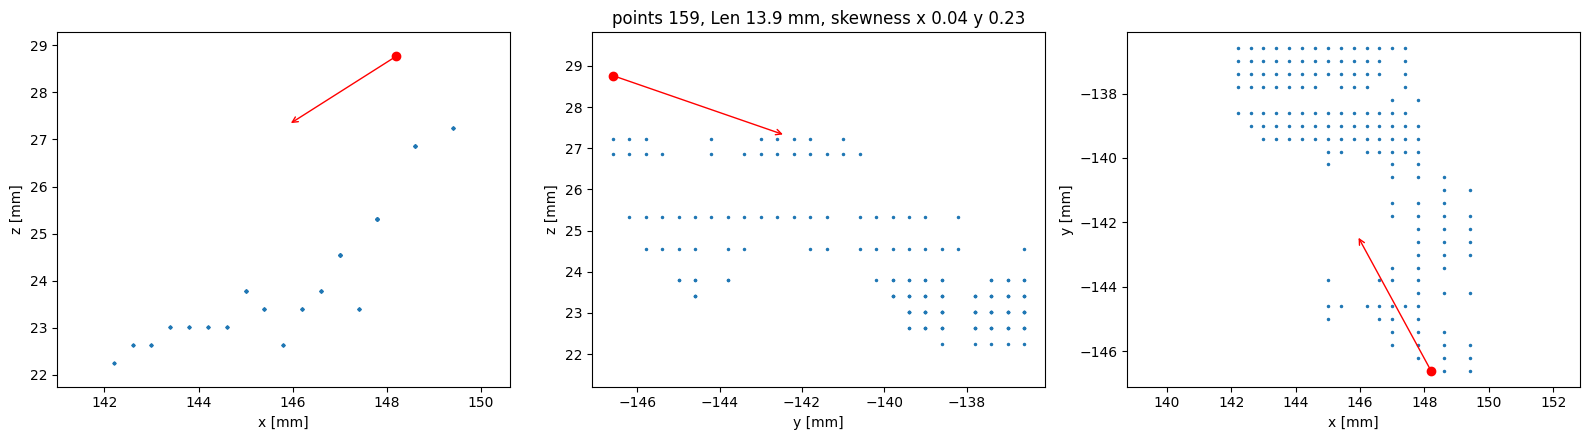

In [4]:
t = ROOT.RDataFrame("TOT_Skewness/tot_skewness", str(OUT)).AsNumpy(["Pe", "Ve", "Len", "skewness_x", "skewness_y", "can", "cloud_x", "cloud_y", "cloud_z"])
can = t["can"]
good_ve = np.array([abs(v[0]) < 1e3 for v in t["Ve"]])
k = int(np.where((can > 80) & (t["Len"] > 10) & (t["Len"] < 60) & good_ve)[0][3])   # まとまった飛跡のイベント
cx, cy, cz = (np.asarray(t[c][k]) for c in ("cloud_x", "cloud_y", "cloud_z"))
pe, ve = np.asarray(t["Pe"][k]), np.asarray(t["Ve"][k])
ve = ve / np.linalg.norm(ve)   # Ve は方向だけ。使う側で正規化する
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, (u, v, iu, iv, nu, nv) in zip(ax, [(cx, cz, 0, 2, "x", "z"), (cy, cz, 1, 2, "y", "z"), (cx, cy, 0, 1, "x", "y")]):
    a.plot(u, v, ".", ms=3)
    a.plot(pe[iu], pe[iv], "ro")
    if np.all(np.isfinite(ve)):
        a.annotate("", xy=(pe[iu] + 5 * ve[iu], pe[iv] + 5 * ve[iv]), xytext=(pe[iu], pe[iv]), arrowprops=dict(arrowstyle="->", color="r"))
    a.set_xlabel(f"{nu} [mm]"); a.set_ylabel(f"{nv} [mm]"); a.set_aspect("equal", adjustable="datalim")
ax[1].set_title(f"points {can[k]}, Len {t['Len'][k]:.1f} mm, skewness x {t['skewness_x'][k]:.2f} y {t['skewness_y'][k]:.2f}")
fig.tight_layout(); plt.show()

## 4. 分布

飛程 `Len`、点の数 `can`、skewness、散乱点の位置です。`Ve` が求まらなかったイベントは `Ve = 0xffffffff`(4.29e9)のままです。

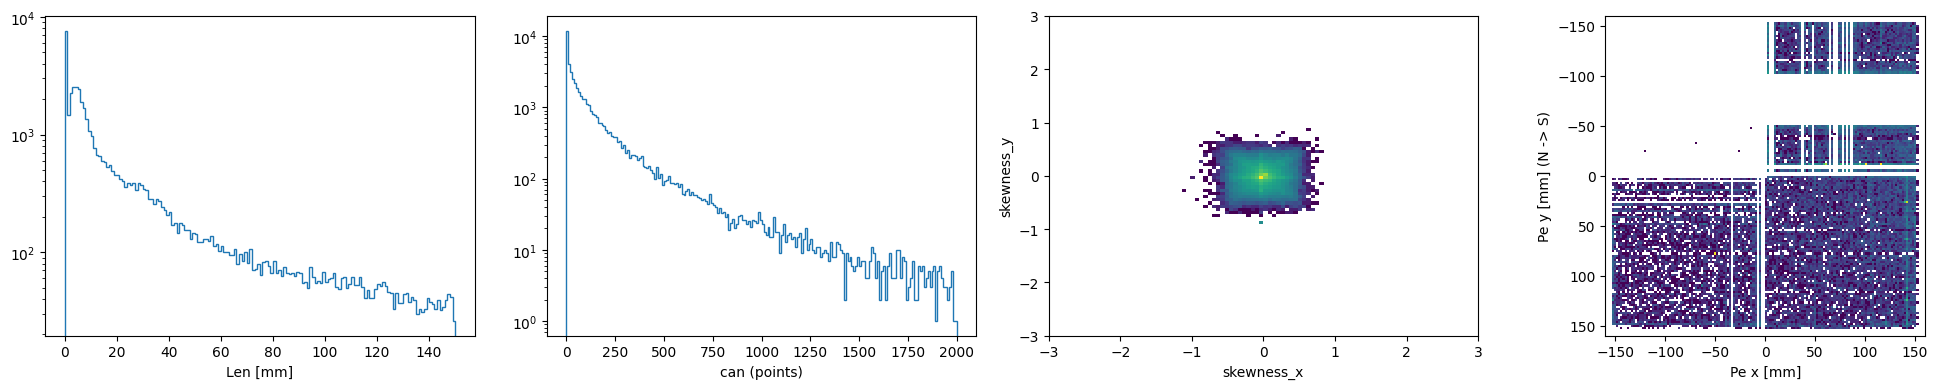

tree rows: 49578  with Ve: 41854


In [5]:
ok = np.abs(np.array([v[0] for v in t["Ve"]])) < 1e5
pe = np.stack(vec(t["Pe"]))
fig, axs = plt.subplots(1, 4, figsize=(20, 4))
axs[0].hist(t["Len"], bins=150, range=(0, 150), histtype="step"); axs[0].set_xlabel("Len [mm]"); axs[0].set_yscale("log")
axs[1].hist(can, bins=200, range=(0, 2000), histtype="step"); axs[1].set_xlabel("can (points)"); axs[1].set_yscale("log")
axs[2].hist2d(t["skewness_x"], t["skewness_y"], bins=100, range=[[-3, 3], [-3, 3]], norm=LogNorm()); axs[2].set_xlabel("skewness_x"); axs[2].set_ylabel("skewness_y")
valid = np.abs(pe[:, 0]) < 1e5
axs[3].hist2d(pe[valid, 0], pe[valid, 1], bins=150, range=[[-160, 160], [-160, 160]], norm=LogNorm()); axs[3].invert_yaxis()
axs[3].set_xlabel("Pe x [mm]"); axs[3].set_ylabel("Pe y [mm] (N -> S)"); axs[3].set_aspect("equal")
fig.tight_layout(); plt.show()
print("tree rows:", len(can), " with Ve:", int(ok.sum()))

`TOT_Skewness/TPC_Map_xz` は、飛跡の両端の x と z です。z の分布の下の端(μ-PIC に近い側)がトリガーの時刻、上の端がドリフト領域の端に当たります。
`clock_offset` と `pitch_z_mm_per_clock`(ドリフト速度)は、EricaNext_try の `4_MakeCalibration/DriftVelocity` と同じ方法でこのような分布から決めます。SMILE-3 ではまだ決めていません(ドリフト速度を測れる測定がまだ)。今は SMILE-2+ の典型値(0.383 mm/クロック、85 クロック)を使っていて、`TOT_Skewness` は「較正ファイル(`drift_velocity_file`)が要る」と警告を出します。

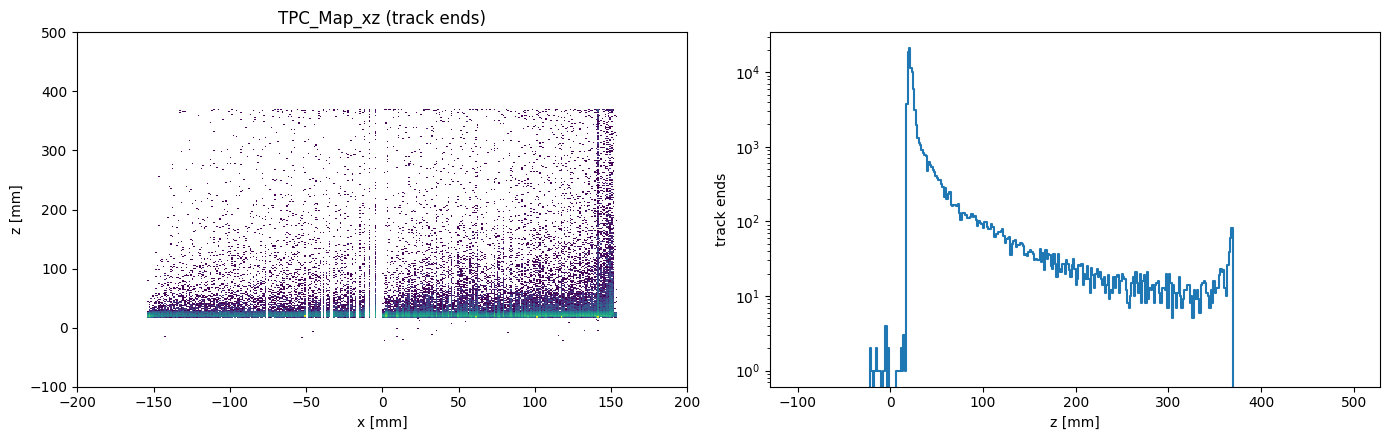

In [6]:
a, ex, ey = th2(F.Get("TOT_Skewness/TPC_Map_xz"))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].pcolormesh(ex, ey, a.T, norm=LogNorm(vmin=1), shading="flat"); ax[0].set_xlabel("x [mm]"); ax[0].set_ylabel("z [mm]"); ax[0].set_title("TPC_Map_xz (track ends)")
ax[1].step(ey[:-1], a.sum(axis=0), where="post"); ax[1].set_xlabel("z [mm]"); ax[1].set_ylabel("track ends"); ax[1].set_yscale("log")
fig.tight_layout(); plt.show()

## 5. パラメータ

In [7]:
show_params("smile3_tpc_only", "TOT_Skewness")

pitch_x_mm_per_strip = 0.4 [mm/strip]
    アノードのストリップの間隔(x)[mm/strip]
pitch_y_mm_per_strip = 0.4 [mm/strip]
    カソードのストリップの間隔(y)[mm/strip]
pitch_z_mm_per_clock = 0.383 [mm/clock]
    ドリフト速度。drift_velocity_file が無いときだけ使う。z = pitch_z × (クロック − clock_offset) + z_gem_mm。今は SMILE-2+ の典型値(2019-07-01 Per02/Per03 の drift_velocity.dat の平均 0.383)で、SMILE-3 の測定はまだ [mm/clock]
clock_offset = 85.0 [clock]
    GEM 面で電離した電子が届くクロック。drift_velocity_file が無いときだけ使う。今は SMILE-2+ の典型値(Per02/Per03 の 85)[clock]
z_gem_mm = 10.0 [mm]
    GEM 面の z(μ-PIC からの距離)。SMILE-3 は 10 mm(SMILE-2+ は 27 mm)。ドリフト長(μ-PIC から天板まで)は 317 mm [mm]
drift_velocity_file = ""
    ドリフト速度の較正ファイル(calib/tpc/。"clock_offset <クロック>" と "velocity <mm/クロック>" の 2 行、# はコメント)。空なら pitch_z_mm_per_clock と clock_offset を使い、較正ファイルが要ると警告を出す。SMILE-3 の較正ファイルはまだ無い(ドリフト速度を測れる測定がまだ)
flag_pixel_cut = false
    true: PixelMask で選んだピクセルを除く(今の PixelMask は除くピクセルが無く、h_cut_pixel に詰めるだけ)
flag_save_cloud = true
    true: 飛跡の点群(cloud_x, cloud_y, cloud_z)を tot_skewness ツリーに保存